In [ ]:
## 1. Environment Setup & Library Installation
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
!pip install git+https://github.com/hallpaz/synthdataseg.git

  Cloning https://github.com/hallpaz/synthdataseg.git to /tmp/pip-req-build-e8109e07
  Running command git clone --filter=blob:none --quiet https://github.com/hallpaz/synthdataseg.git /tmp/pip-req-build-e8109e07
  Resolved https://github.com/hallpaz/synthdataseg.git to commit d5ed00f416bb836e0942de5cd873a41ef59e46a6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import synthdataseg
from synthdataseg.dataset import SyntheticSegmentationDataset

In [ ]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

class UNetSurrogate(nn.Module):
    def __init__(self, in_channels, num_classes, up_channels=32):
        super().__init__()
        self.down1 = DoubleConv(in_channels, up_channels)
        self.pool1 = nn.MaxPool2d(2)
        self.down2 = DoubleConv(up_channels, 2*up_channels)
        self.pool2 = nn.MaxPool2d(2)
        self.down3 = DoubleConv(2*up_channels, 4*up_channels)
        self.pool3 = nn.MaxPool2d(2)
        self.down4 = DoubleConv(4*up_channels, 8*up_channels)

        self.up1 = nn.ConvTranspose2d(8*up_channels, 4*up_channels, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(8*up_channels, 4*up_channels)
        self.up2 = nn.ConvTranspose2d(4*up_channels, 2*up_channels, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(4*up_channels, 2*up_channels)
        self.up3 = nn.ConvTranspose2d(2*up_channels, up_channels, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(2*up_channels, up_channels)

        self.out = nn.Conv2d(up_channels, num_classes, kernel_size=1)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool1(d1))
        d3 = self.down3(self.pool2(d2))
        bottleneck = self.down4(self.pool3(d3))

        u1 = self.up1(bottleneck)
        u1 = torch.cat([u1, d3], dim=1)
        u1 = self.conv_up1(u1)

        u2 = self.up2(u1)
        u2 = torch.cat([u2, d2], dim=1)
        u2 = self.conv_up2(u2)

        u3 = self.up3(u2)
        u3 = torch.cat([u3, d1], dim=1)
        u3 = self.conv_up3(u3)

        return self.out(u3)

In [ ]:
# Define the directory path and model file path
save_dir = '/content/drive/MyDrive/research/segmentation/'
save_path = os.path.join(save_dir, 'unet_surrogate_8sh_32up_10ep.pth')

In [ ]:
BATCH_SIZE = 64
num_classes = 8
IMG_SIZE = (256, 256)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training surrogate model on: {device}")

train_dataset = SyntheticSegmentationDataset(num_samples=8000,
                                             image_size=IMG_SIZE,
                                             max_n=num_classes-1,
                                             min_shapes=1,
                                             max_shapes=4)

val_dataset = SyntheticSegmentationDataset(num_samples=1600,
                                           image_size=IMG_SIZE,
                                           max_n=num_classes-1,
                                           min_shapes=1,
                                           max_shapes=4)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model = UNetSurrogate(in_channels=3, num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
epochs = 10

Training surrogate model on: cpu


In [ ]:
print("Commencing surrogate training...")
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Quick validation pass
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            val_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

# Freeze the surrogate model for future bilevel optimization
for param in model.parameters():
    param.requires_grad = False
model.eval()

Commencing surrogate training...
Epoch 1/10 | Train Loss: 1.1542 | Val Loss: 0.7212
Epoch 2/10 | Train Loss: 0.6167 | Val Loss: 0.5918
Epoch 3/10 | Train Loss: 0.5455 | Val Loss: 0.6025
Epoch 4/10 | Train Loss: 0.5049 | Val Loss: 0.5155
Epoch 5/10 | Train Loss: 0.4787 | Val Loss: 0.4780
Epoch 6/10 | Train Loss: 0.4520 | Val Loss: 0.4741
Epoch 7/10 | Train Loss: 0.4304 | Val Loss: 0.4242
Epoch 8/10 | Train Loss: 0.4104 | Val Loss: 0.4094
Epoch 9/10 | Train Loss: 0.3953 | Val Loss: 0.3960
Epoch 10/10 | Train Loss: 0.3873 | Val Loss: 0.3906


UNetSurrogate(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_runnin

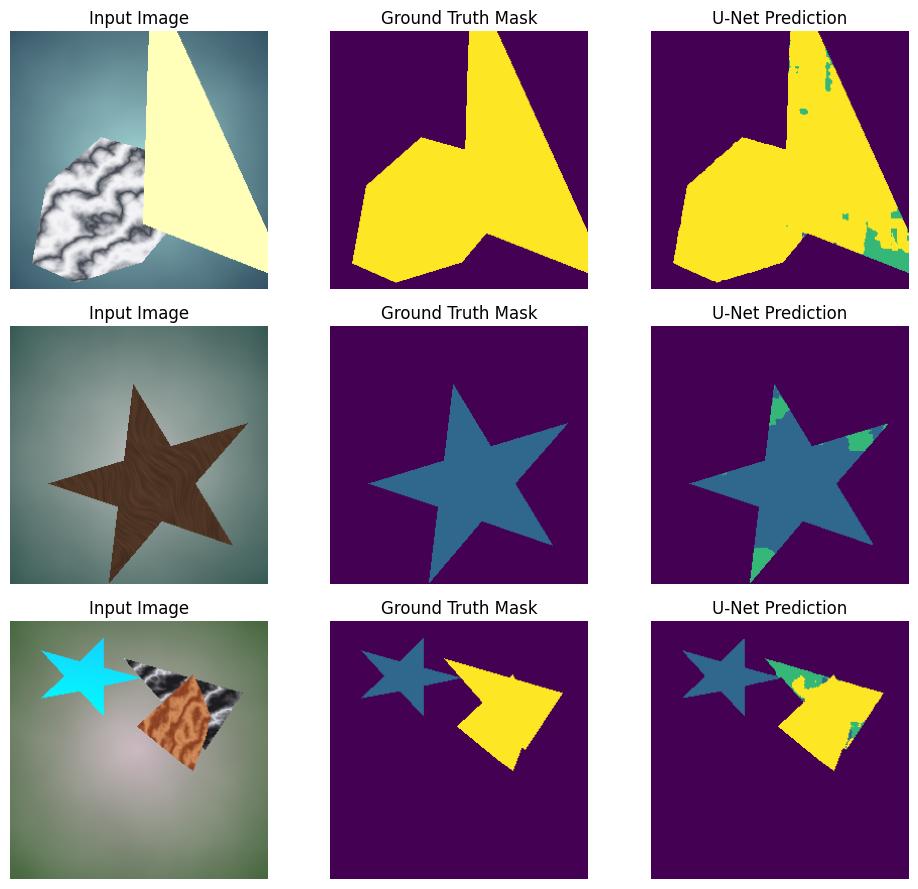

In [ ]:
def visualize_predictions(model, loader, num_images=3):
    model.eval()
    images, masks = next(iter(loader))
    images, masks = images.to(device), masks.to(device)

    with torch.no_grad():
        logits = model(images)
        preds = torch.argmax(logits, dim=1)

    images = images.cpu().numpy()
    masks = masks.cpu().numpy()
    preds = preds.cpu().numpy()

    fig, axes = plt.subplots(num_images, 3, figsize=(10, 3 * num_images))
    for i in range(num_images):
        # Swap axes from (C, H, W) to (H, W, C) for plotting
        img_plot = np.transpose(images[i], (1, 2, 0))

        axes[i, 0].imshow(img_plot)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(masks[i], cmap='viridis', vmin=0, vmax=3)
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis('off')

        axes[i, 2].imshow(preds[i], cmap='viridis', vmin=0, vmax=3)
        axes[i, 2].set_title("U-Net Prediction")
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

visualize_predictions(model, val_loader)

In [ ]:
# Create the directory if it does not exist
os.makedirs(save_dir, exist_ok=True)

# Save the model state dictionary
torch.save(model.state_dict(), save_path)
print(f"Model weights successfully saved to {save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model weights successfully saved to /content/drive/MyDrive/research/segmentation/unet_surrogate_8sh_32up_10ep.pth


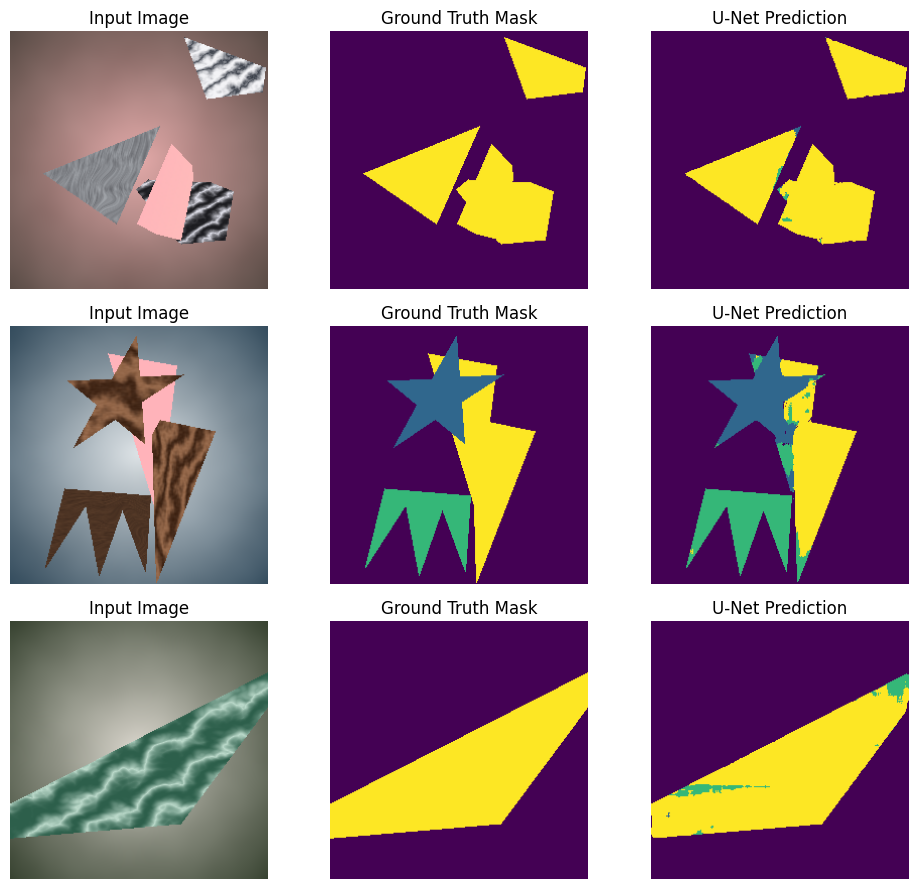

In [ ]:
visualize_predictions(model, val_loader)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Training surrogate model on: {device}")
device = torch.device(device)
# 1. Load the saved weights
save_path = "/content/drive/MyDrive/research/segmentation/unet_surrogate_8sh_32up_20ep.pth"
print(f"Loading model weights from {save_path}...")
model.load_state_dict(torch.load(save_path, map_location=device))

# 2. Re-enable gradients for all parameters so we can continue training
for param in model.parameters():
    param.requires_grad = True

Training surrogate model on: cpu
Loading model weights from /content/drive/MyDrive/research/segmentation/unet_surrogate_8sh_32up_20ep.pth...


In [ ]:
# 3. Define additional epochs to train
additional_epochs = 10
total_epochs = epochs + additional_epochs
print(f"Continuing training from epoch {epochs} to {total_epochs}...")

# 4. Resume the training loop
for epoch in range(epochs, total_epochs):
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation pass
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            val_loss += loss.item()

    print(f"Epoch {epoch+1}/{total_epochs} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

# Save the model state dictionary
save_path = os.path.join(save_dir, 'unet_surrogate_8sh_32up_20ep.pth')
torch.save(model.state_dict(), save_path)
print(f"Model weights successfully saved to {save_path}")

Loading model weights from /content/drive/MyDrive/research/segmentation/unet_surrogate_8sh_32up_10ep.pth...
Continuing training from epoch 10 to 20...
Epoch 11/20 | Train Loss: 0.3764 | Val Loss: 0.3787
Epoch 12/20 | Train Loss: 0.3732 | Val Loss: 0.3718
Epoch 13/20 | Train Loss: 0.3677 | Val Loss: 0.3672
Epoch 14/20 | Train Loss: 0.3566 | Val Loss: 0.3628
Epoch 15/20 | Train Loss: 0.3567 | Val Loss: 0.3621
Epoch 16/20 | Train Loss: 0.3508 | Val Loss: 0.3834
Epoch 17/20 | Train Loss: 0.3510 | Val Loss: 0.3636
Epoch 18/20 | Train Loss: 0.3451 | Val Loss: 0.3456
Epoch 19/20 | Train Loss: 0.3402 | Val Loss: 0.3764
Epoch 20/20 | Train Loss: 0.3426 | Val Loss: 0.3404
Model weights successfully saved to /content/drive/MyDrive/research/segmentation/unet_surrogate_8sh_32up_20ep.pth


In [ ]:
from PIL import Image
import torchvision.transforms as T

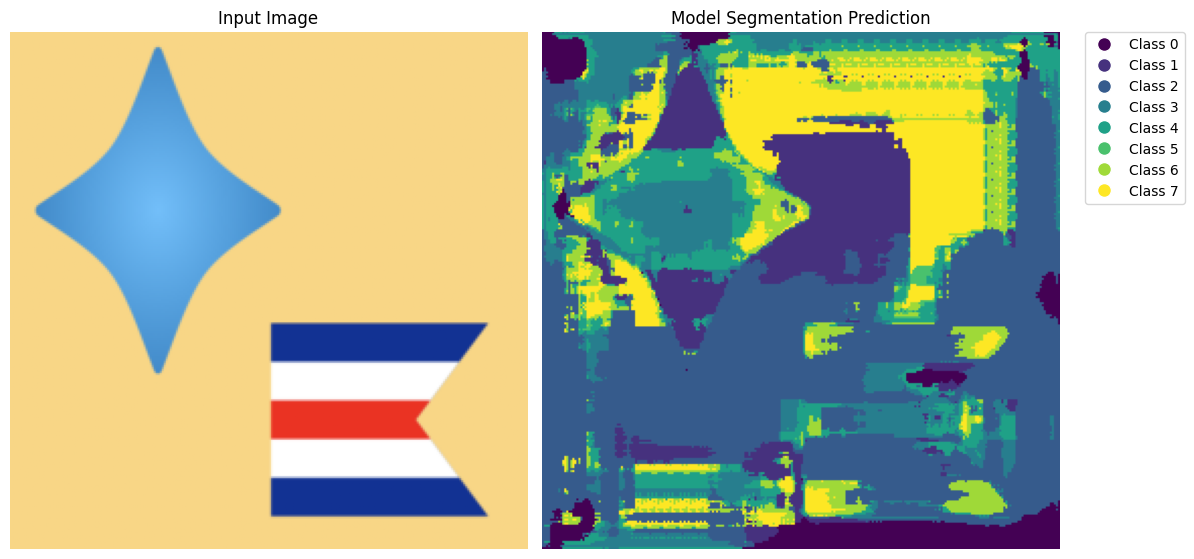

In [ ]:
# 1. Define image path and load image
image_path = "/content/key-image-neutral.001.png"
img = Image.open(image_path).convert("RGB")

# 2. Preprocess the image (resize and convert to float tensor)
transform = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor(),  # scale pixels to [0, 1] and transpose to (C, H, W)
])

img_tensor = transform(img).unsqueeze(0).to(device)  # Add batch dimension and move to device

# 3. Perform inference
model.eval()
with torch.no_grad():
    logits = model(img_tensor)
    pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

# 4. Convert processed image tensor back to numpy for visualization
img_visualize = img_tensor.squeeze(0).cpu().permute(1, 2, 0).numpy()

# 5. Visualize input and prediction side-by-side with a color legend
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_visualize)
axes[0].set_title("Input Image")
axes[0].axis("off")

# Show prediction with class boundaries mapped to 8 classes
im = axes[1].imshow(pred, cmap="viridis", vmin=0, vmax=7)
axes[1].set_title("Model Segmentation Prediction")
axes[1].axis("off")

# Define the labels for each of the 8 classes in synthetic dataset
class_names = [f"Class {i}" for i in range(8)]

# Create a discrete color legend mapping color to each class
colors = [im.cmap(im.norm(i)) for i in range(8)]
patches = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=colors[i], markersize=10, label=class_names[i]) for i in range(8)]
axes[1].legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()

In [ ]:
# 5. Freeze the surrogate model again for future tasks
for param in model.parameters():
    param.requires_grad = False
model.eval()
print("Training completed and model frozen.")

#TODO: measure the receptive field